In [50]:
# Imports
import sys; sys.path.append("..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import time
from scipy import ndimage as ndi
from src.datos import cargar_inventario, a_gris
from src.preproceso import mascara_cerebral, normalizar, a_tamano_comun, preprocesar
from skimage import morphology, measure
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.cluster import KMeans    

## 1. Selección de imágenes de prueba

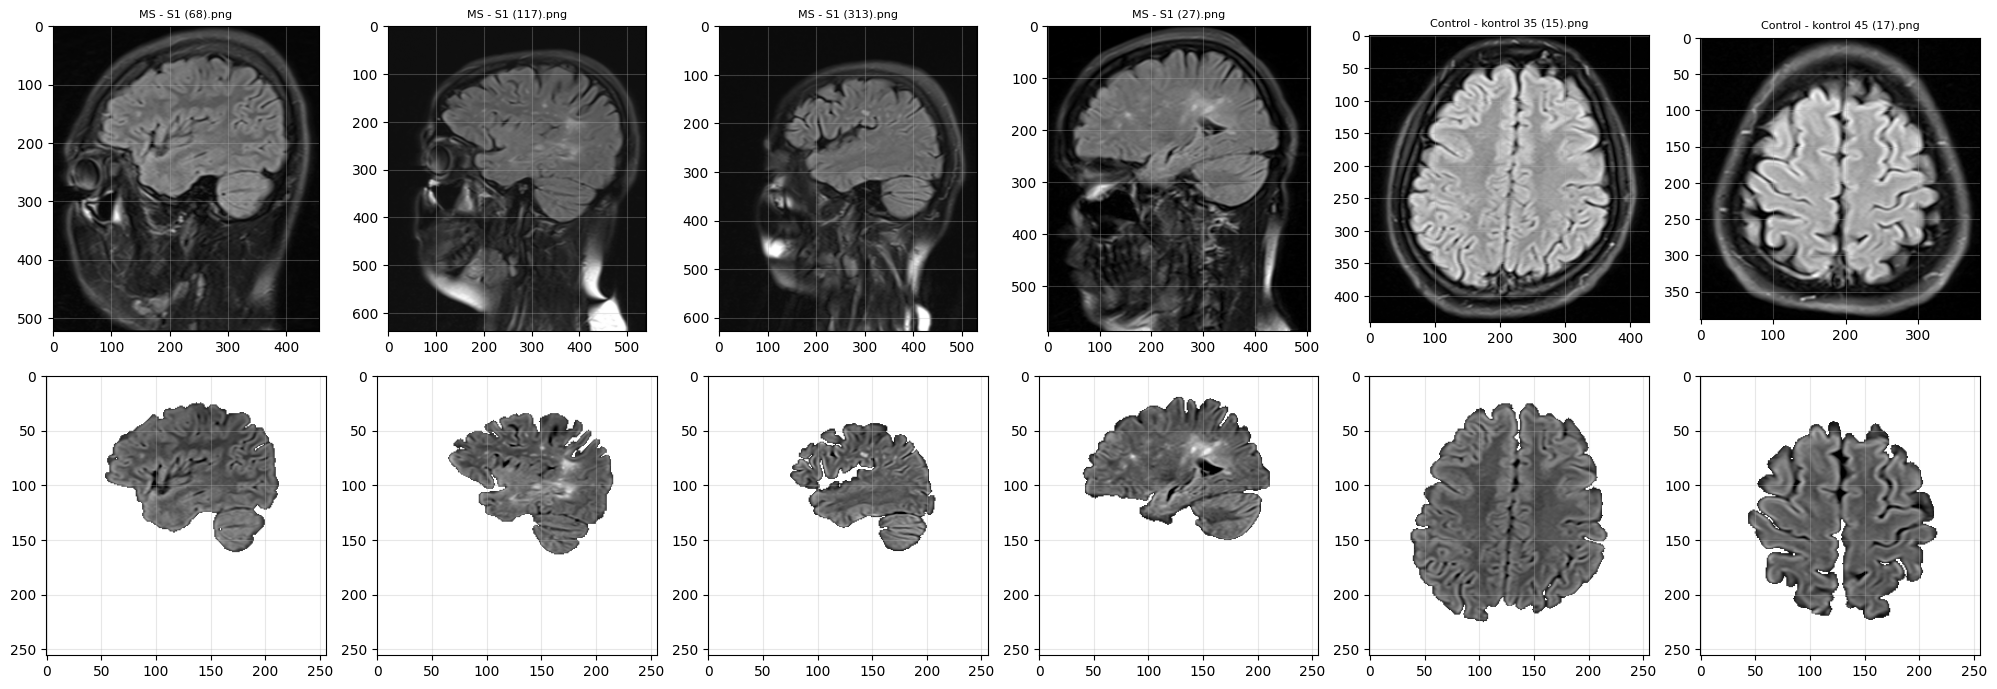

In [11]:
# Imprimimos 6 cortes al azar, junto con su máscara cerebral, para encontrar tejido lesionado para segmentar
df = cargar_inventario()

prueba = pd.concat([df[(df["Clase"] == "MS") & (df["Corte"] == "Sagital")].sample(4),
                    df[(df["Clase"] == "Control") & (df["Corte"] == "Axial")].sample(2)])

fig, axs = plt.subplots(2, 6, figsize=(20, 7))
for j, (_, r) in enumerate(prueba.iterrows()):
    z, mask = preprocesar(r["ruta"])
    axs[0, j].imshow(a_gris(r["ruta"]), cmap="gray")
    axs[0, j].set_title(f"{r['Clase']} - {r['ruta'].name}", fontsize=8)
    axs[1, j].imshow(np.where(mask, z, np.nan), cmap="gray", vmin=-3, vmax=5)
for a in axs.ravel():
    a.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

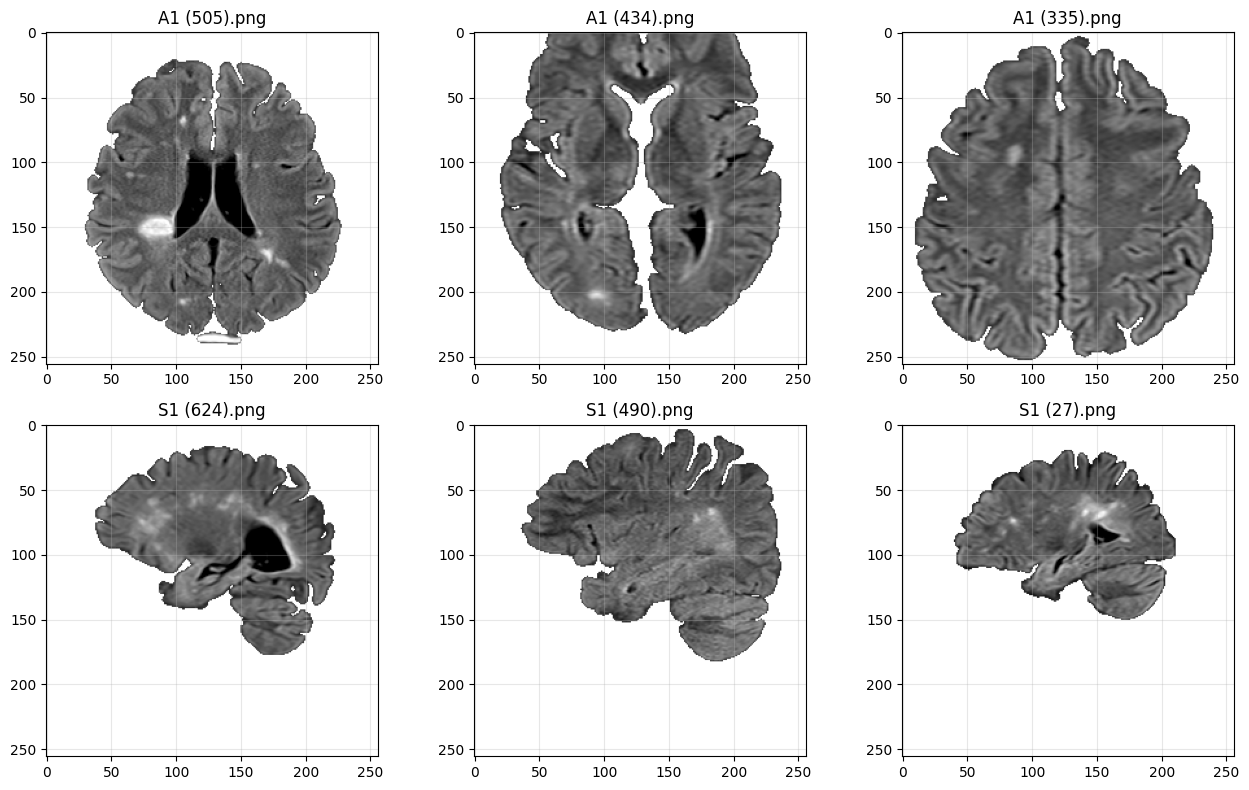

In [16]:
# Imágenes seleccionadas
fijas = ["A1 (505).png", "A1 (434).png", "A1 (335).png", "S1 (624).png", "S1 (490).png", "S1 (27).png"]
sel = df[df["ruta"].apply(lambda p: p.name).isin(fijas)].copy()
sel["orden"] = sel["ruta"].apply(lambda p: fijas.index(p.name))
sel = sel.sort_values("orden")

datos = {r["ruta"].name: preprocesar(r["ruta"]) for _, r in sel.iterrows()}   # nombre -> (z, máscara) a 256x256
assert len(datos) == 6, f"Se encontraron {len(datos)} de 6 imágenes: revisá los nombres"

fig, axs = plt.subplots(2, 3, figsize=(13, 8))
for ax, (nombre, (z, mask)) in zip(axs.ravel(), datos.items()):
    ax.imshow(np.where(mask, z, np.nan), cmap="gray", vmin=-3, vmax=5)
    ax.set_title(nombre)
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Método Region Growing

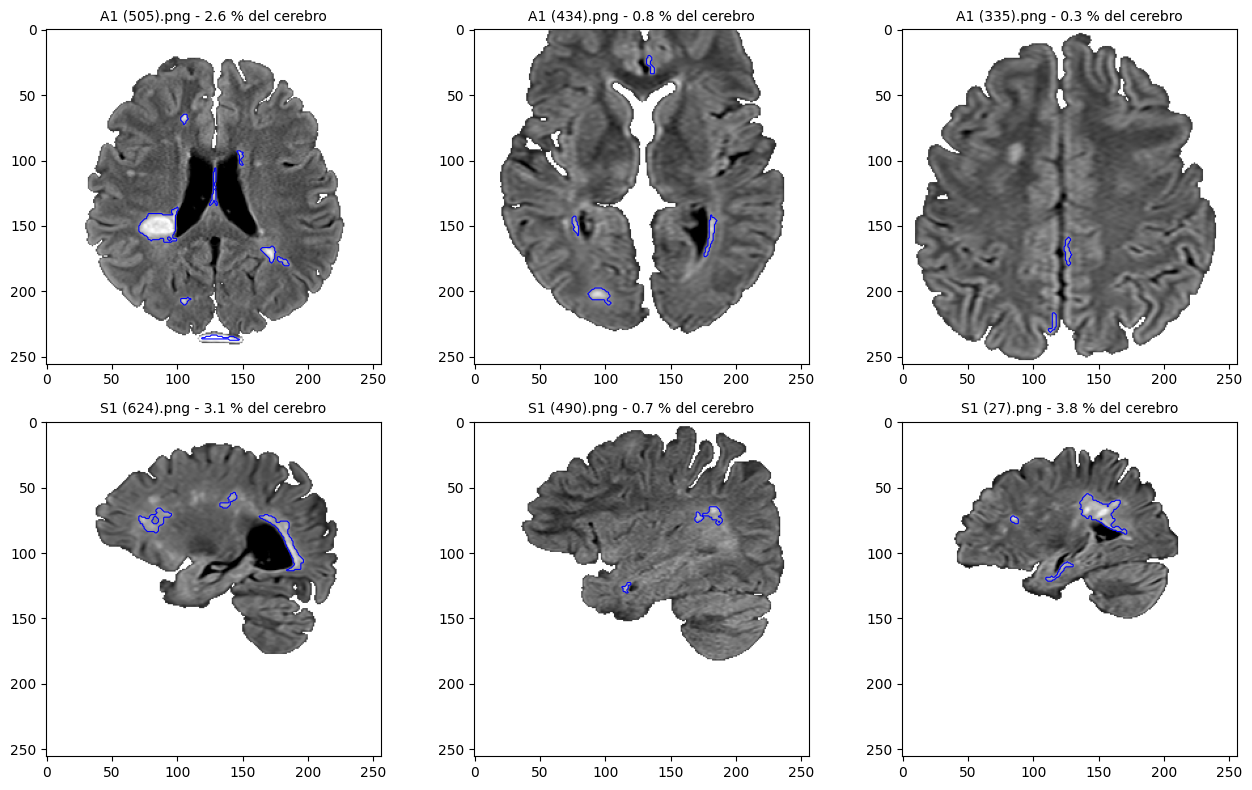

In [31]:
T_ALTO = 2.5       # semillas: píxeles con z por encima de este valor
T_BAJO = 1.5     # crecimiento: se agregan vecinos conectados con z por encima de este valor
AREA_MIN = 25    # px (en 256x256): descarta regiones diminutas
EROSION = 3      # px: se achica la máscara para no tomar el borde del cerebro

def region_growing(z, mask, t_alto=T_ALTO, t_bajo=T_BAJO, area_min=AREA_MIN, erosion=EROSION):
    interior = ndi.binary_erosion(mask, structure=morphology.disk(erosion))
    candidatos = (z > t_bajo) & interior
    lab = measure.label(candidatos, connectivity=2) #Conectividad 2 para 8 vecinos, cuenta las diagonales
    semillas = np.unique(lab[(z > t_alto) & interior])
    semillas = semillas[semillas > 0]
    seg = np.isin(lab, semillas)
    return morphology.remove_small_objects(seg, area_min)

fig, axs = plt.subplots(2, 3, figsize=(13, 8))
for ax, (nombre, (z, mask)) in zip(axs.ravel(), datos.items()):
    seg = region_growing(z, mask)
    ax.imshow(np.where(mask, z, np.nan), cmap="gray", vmin=-3, vmax=5)
    if seg.any():
        ax.contour(seg.astype(float), levels=[0.5], colors="b", linewidths=0.8)
    ax.set_title(f"{nombre} - {100 * seg.sum() / mask.sum():.1f} % del cerebro", fontsize=10)
plt.tight_layout()
plt.show()

&ensp; El primer método probado es Region Growing. Se toman como **semillas** los píxeles muy brillantes de la imagen normalizada (z > T_alto = 2,5) dentro de la máscara cerebral (erosionada 3 px para evitar el borde), y cada región crece hacia los vecinos conectados cuyo z supere 1,5. Equivale a una umbralización porque solo se marcan regiones brillantes que contienen al menos una semilla. Se descartan regiones de menos de 25 px (en la imagen de 256 × 256).

**Desempeño.** El método marca entre el 0,3 % y el 3,8 % del cerebro y detecta las hiperintensidades más evidentes (por ejemplo, la lesión periventricular de `A1 (505)` y la de `S1 (27)`).

&ensp: Sin embargo, el método presenta algunas limitaciones:  

- **Falsos negativos:** no detecta manchas tenues, como la de la región superior izquierda de `A1 (335)`, que no alcanza el umbral de las semillas. Bajar el umbral a 2 la capta, pero aumentan los falsos positivos.

- **Posibles falsos positivos:** varias marcas se ubican sobre el borde de los ventrículos, el borde posterior del cerebro y la cisura interhemisférica, donde la mezcla de tejido y líquido produce intensidades altas sin ser necesariamente lesión. Los bordes periventriculares son también un sitio típico de lesiones de EM, por lo que con este método no se pueden distinguir.

- El resultado depende de los umbrales (compromiso entre sensibilidad y falsos positivos) y no se pudo validar con anotaciones de un especialista.

## 2. Umbralización adaptativa

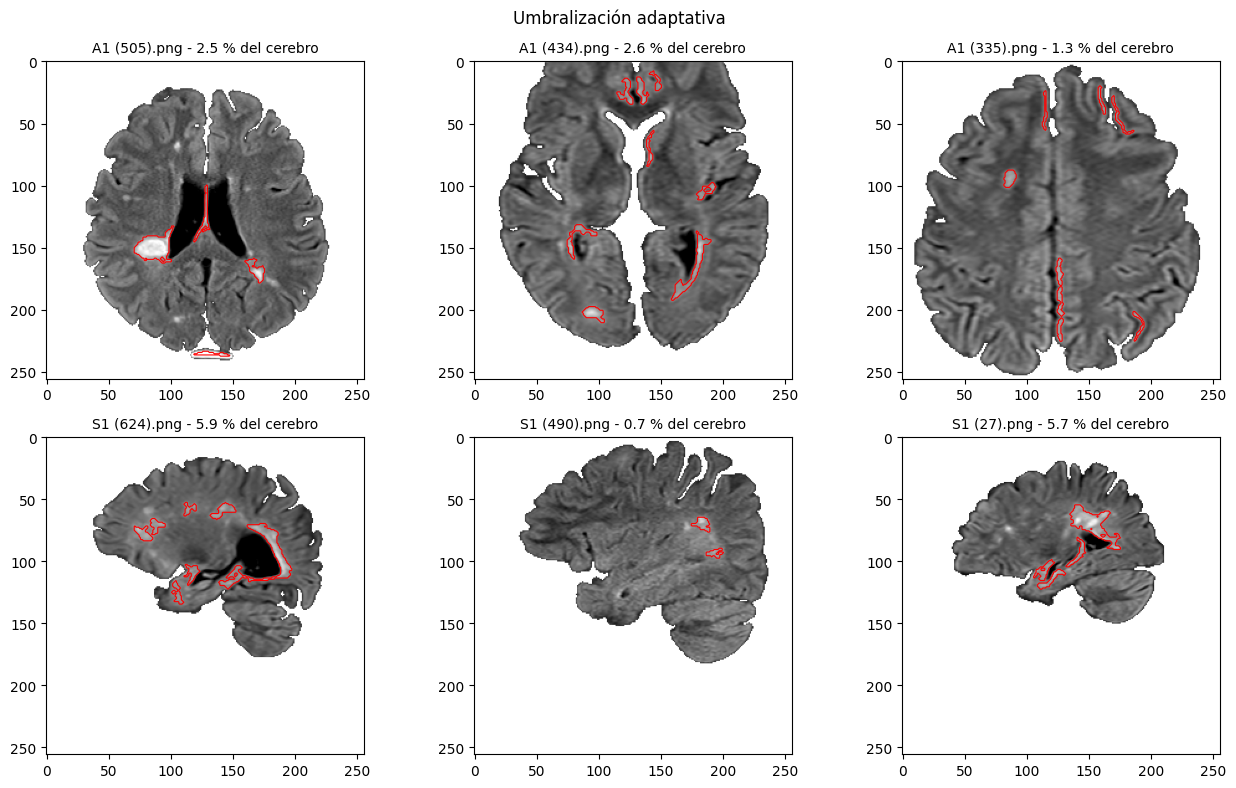

In [37]:
SIGMA = 15     # px: tamaño del vecindario local (gaussiano)
OFFSET = 1     # candidato si supera la media local en esta cantidad (unidades de z)
Z_MIN = 1      # y además tiene que superar este z absoluto

def umbral_adaptativo(z, mask, sigma=SIGMA, offset=OFFSET, z_min=Z_MIN, area_min=AREA_MIN, erosion=EROSION):
    m = mask.astype(float)
    media_local = ndi.gaussian_filter(z * m, sigma) / np.maximum(ndi.gaussian_filter(m, sigma), 1e-6)
    interior = ndi.binary_erosion(mask, structure=morphology.disk(erosion))
    seg = (z > media_local + offset) & (z > z_min) & interior
    return morphology.remove_small_objects(seg, area_min)

def mostrar(metodo, titulo):
    fig, axs = plt.subplots(2, 3, figsize=(13, 8))
    for ax, (nombre, (z, mask)) in zip(axs.ravel(), datos.items()):
        seg = metodo(z, mask, area_min=50)
        ax.imshow(np.where(mask, z, np.nan), cmap="gray", vmin=-3, vmax=5)
        if seg.any():
            ax.contour(seg.astype(float), levels=[0.5], colors="r", linewidths=0.8)
        ax.set_title(f"{nombre} - {100 * seg.sum() / mask.sum():.1f} % del cerebro", fontsize=10)
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

mostrar(umbral_adaptativo, "Umbralización adaptativa")

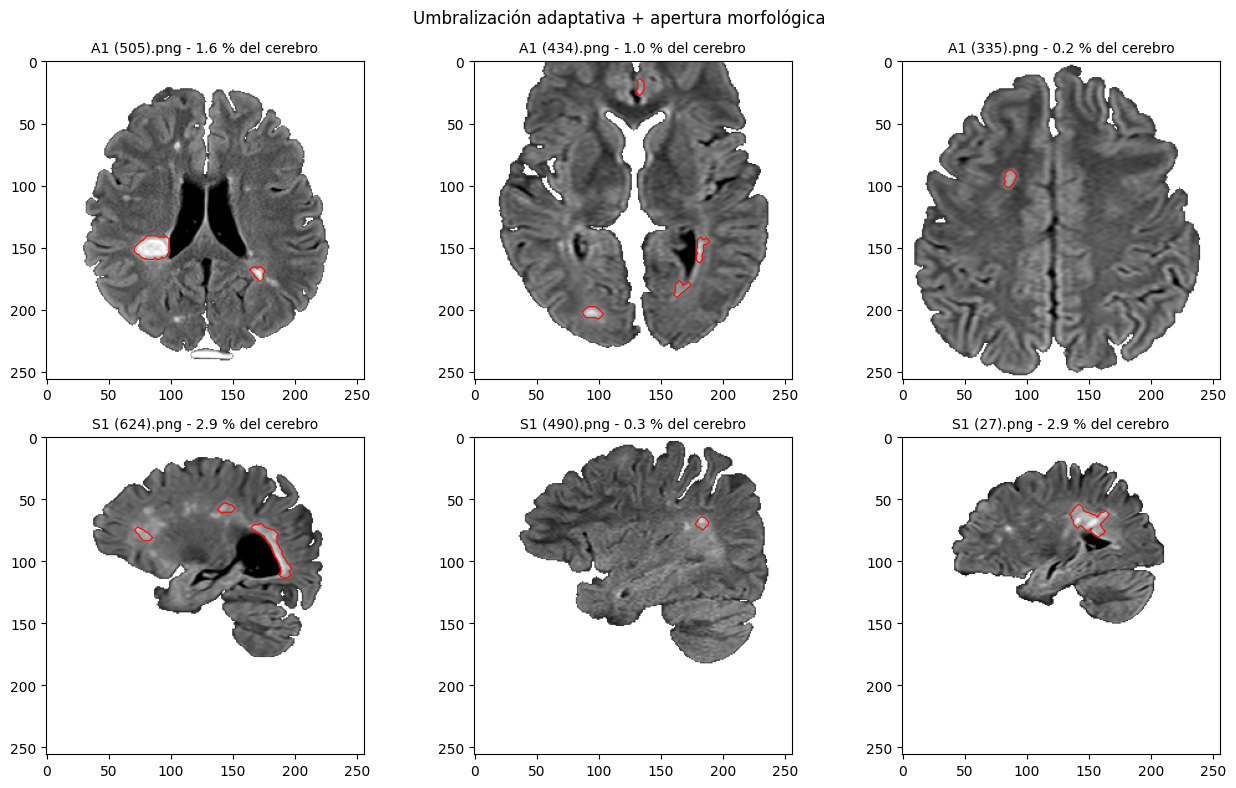

In [ ]:
# Agregamos apertura morfológica para eliminar falsos positivos
APERTURA = 2   # radio (px) del disco de la apertura: elimina estructuras más finas que 2*APERTURA+1 px

def umbral_adaptativo(z, mask, sigma=SIGMA, offset=OFFSET, z_min=Z_MIN, area_min=AREA_MIN,
                      erosion=EROSION, apertura=APERTURA):
    m = mask.astype(float)
    media_local = ndi.gaussian_filter(z * m, sigma) / np.maximum(ndi.gaussian_filter(m, sigma), 1e-6)
    interior = ndi.binary_erosion(mask, structure=morphology.disk(erosion))
    seg = (z > media_local + offset) & (z > z_min) & interior
    if apertura > 0:
        seg = ndi.binary_opening(seg, structure=morphology.disk(apertura))   # saca tiras finas
    return morphology.remove_small_objects(seg, area_min)

mostrar(umbral_adaptativo, "Umbralización adaptativa + apertura morfológica")

&ensp; En lugar de un umbral global, cada píxel se compara contra la media de su vecindario, calculada con un filtro gaussiano (σ = 15 px) solo sobre los píxeles dentro de la máscara cerebral (así el fondo no sesga la media cerca de los bordes). Un píxel es candidato a lesión si supera esa media local en 1 unidad de z (`OFFSET`), tiene z > 1 (`Z_MIN`) y está dentro de la máscara erosionada 3 px. Finalmente se descartan regiones de menos de 50 px (en la imagen de 256 × 256).

**Resultado sin apertura.** Respecto de region growing, este método detecta además manchas tenues que el primero no veía, como la de la región superior izquierda de `A1 (335)`, porque lo que cuenta es el contraste con el entorno y no el brillo absoluto. Pero marca una cantidad grande de falsos positivos: bordes de los ventrículos, la cisura interhemisférica en `A1 (335)` y el borde posterior del cerebro en `A1 (505)`.

**Observación y corrección.** Al inspeccionar esos falsos positivos notamos que tenían una forma característica: finos y alargados, como un "poroto" o una tira que sigue el contorno de una estructura, mientras que las lesiones son manchas más compactas. Esto sugirió eliminarlos morfológicamente, con una **apertura** (erosión seguida de dilatación con un disco de radio 2 px), que borra las estructuras más finas que el disco y conserva casi sin cambios las regiones más anchas. Se aplica antes del filtro de área.

**Resultado con apertura.** La apertura mejora claramente el resultado ya que desaparecen casi todos los falsos positivos de borde (en `A1 (335)` solo queda marcada la mancha tenue, y se pasa de marcar entre el 1,3 % y el 6,7 % del cerebro a entre el 0,2 % y el 2,9 %), y se siguen detectando las lesiones más evidentes (`A1 (505)`, `S1 (27)`).

**Limitaciones.**
- La apertura puede eliminar lesiones muy pequeñas o finas, como algunos puntos brillantes aislados de `A1 (505)`, y es un compromiso entre falsos positivos y falsos negativos.
- Persisten marcas sobre el borde de los ventrículos (por ejemplo, en `A1 (434)` y `S1 (624)`), que pueden ser lesiones periventriculares reales o artefactos de volumen parcial; con este método no se pueden distinguir.
- La evaluación es cualitativa, sobre 6 cortes de MS y sin anotaciones de un especialista.

## 3. Segmentación por texturas + K-means

Tiempo: 0.8 s


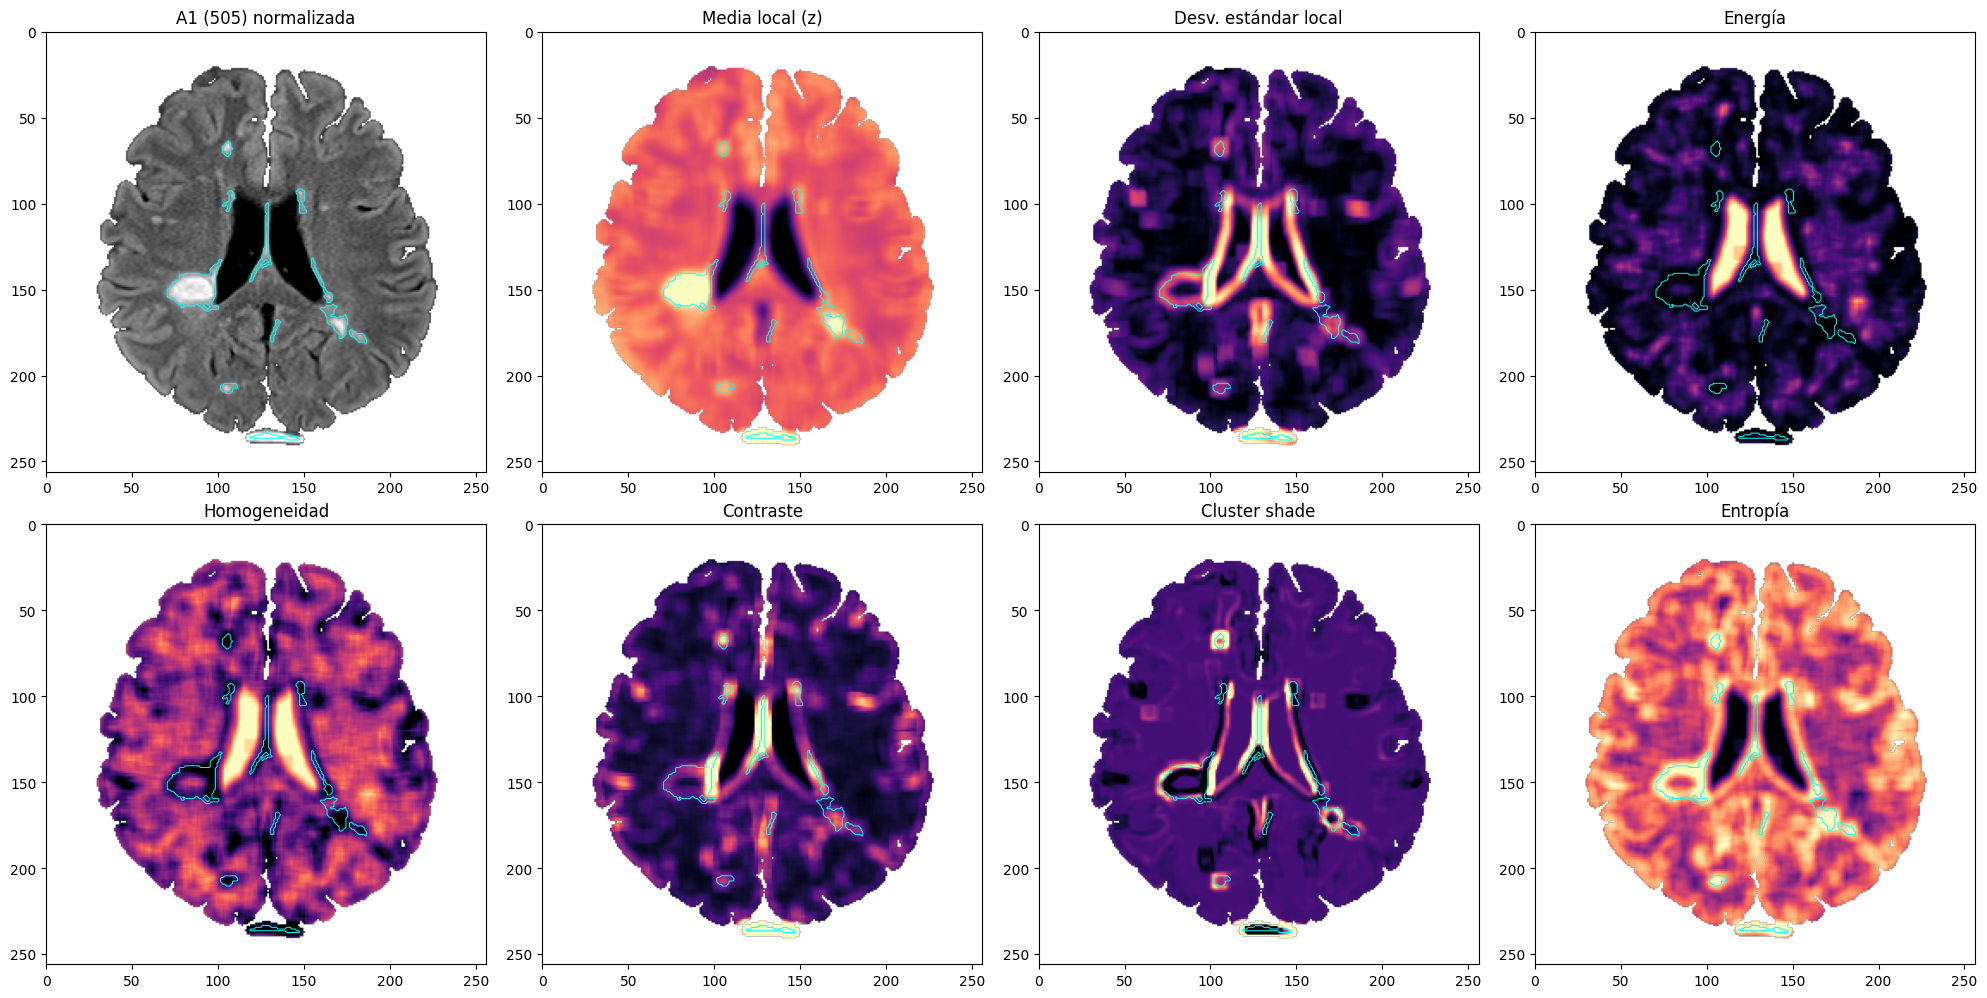

In [49]:
L, VENT, PASO = 16, 9, 1   # niveles de gris, tamaño de ventana (px), paso entre centros (px)

def mapas_textura(z, mask, L=L, ventana=VENT, paso=PASO, zmin=-2, zmax=6):
    w, r = ventana, ventana // 2
    q = (np.clip((z - zmin) / (zmax - zmin), 0, 0.9999) * L).astype(int)      # z -> niveles 0..L-1
    vq = sliding_window_view(q, (w, w))[::paso, ::paso]
    vz = sliding_window_view(z * mask, (w, w))[::paso, ::paso]
    vm = sliding_window_view(mask.astype(float), (w, w))[::paso, ::paso]
    centros = mask[r:-r, r:-r][::paso, ::paso]                                  # solo ventanas centradas en el cerebro
    Q, Z, M = vq[centros], vz[centros], vm[centros]                             # (N, w, w)
    N = len(Q)

    # GLCM: distancia 1, ángulos 0/45/90/135, simétrica, acumulada
    glcm = np.zeros((N, L, L))
    base = np.arange(N)[:, None, None] * L * L
    for dy, dx in [(0, 1), (-1, 1), (-1, 0), (-1, -1)]:
        a = Q[:, max(0, -dy):w - max(0, dy), max(0, -dx):w - max(0, dx)]
        b = Q[:, max(0, dy):w - max(0, -dy), max(0, dx):w - max(0, -dx)]
        c = np.bincount((a * L + b + base).ravel(), minlength=N * L * L).reshape(N, L, L)
        glcm += c + c.transpose(0, 2, 1)
    P = glcm / glcm.sum(axis=(1, 2), keepdims=True)

    i, j = np.indices((L, L))
    mu = (P * i).sum(axis=(1, 2))
    n_px = M.sum(axis=(1, 2))
    media = Z.sum(axis=(1, 2)) / n_px
    desv = np.sqrt(np.maximum((Z ** 2).sum(axis=(1, 2)) / n_px - media ** 2, 0))
    valores = {
        "Media local (z)":   media,
        "Desv. estándar local": desv,
        "Energía":           (P ** 2).sum(axis=(1, 2)),
        "Homogeneidad":      (P / (1 + (i - j) ** 2)).sum(axis=(1, 2)),
        "Contraste":         (P * (i - j) ** 2).sum(axis=(1, 2)),
        "Cluster shade":     (P * (i + j - 2 * mu[:, None, None]) ** 3).sum(axis=(1, 2)),
        "Entropía":          -(P * np.log2(P + 1e-12)).sum(axis=(1, 2)),
    }
    ny, nx = centros.shape
    mapas = {}
    for nombre, v in valores.items():
        m2 = np.full((ny, nx), np.nan)
        m2[centros] = v
        mapas[nombre] = m2
    return mapas

t0 = time.time()
z, mask = datos["A1 (505).png"]
mapas = mapas_textura(z, mask)
print(f"Tiempo: {time.time() - t0:.1f} s")

seg = umbral_adaptativo(z, mask)    # como referencia (contorno cian)
rad = VENT // 2
fig, axs = plt.subplots(2, 4, figsize=(20, 10))
axs[0, 0].imshow(np.where(mask, z, np.nan), cmap="gray", vmin=-3, vmax=5)
axs[0, 0].set_title("A1 (505) normalizada")
for ax, (nombre, m2) in zip(axs.ravel()[1:], mapas.items()):
    ny, nx = m2.shape
    ext = (rad - PASO / 2, rad + PASO * nx - PASO / 2, rad + PASO * ny - PASO / 2, rad - PASO / 2)
    v1, v2 = np.nanpercentile(m2, [2, 98])
    ax.imshow(m2, cmap="magma", vmin=v1, vmax=v2, extent=ext)
    ax.set_title(nombre)
for ax in axs.ravel():
    if seg.any():
        ax.contour(seg.astype(float), levels=[0.5], colors="cyan", linewidths=0.7)
    ax.set_xlim(0, 256)
    ax.set_ylim(256, 0)
plt.tight_layout()
plt.show()

,% de píxeles,Media local (z),Desv. estándar local,Homogeneidad,Cluster shade,Entropía
Cluster,,,,,,
0,37.40,0.15,0.58,0.71,-1.83,3.70
1,44.78,-0.19,0.33,0.83,0.67,2.41
2,10.32,0.29,0.95,0.65,-25.18,4.27
3,7.50,-0.31,1.18,0.69,42.03,3.94


Cluster elegido como lesión: 2


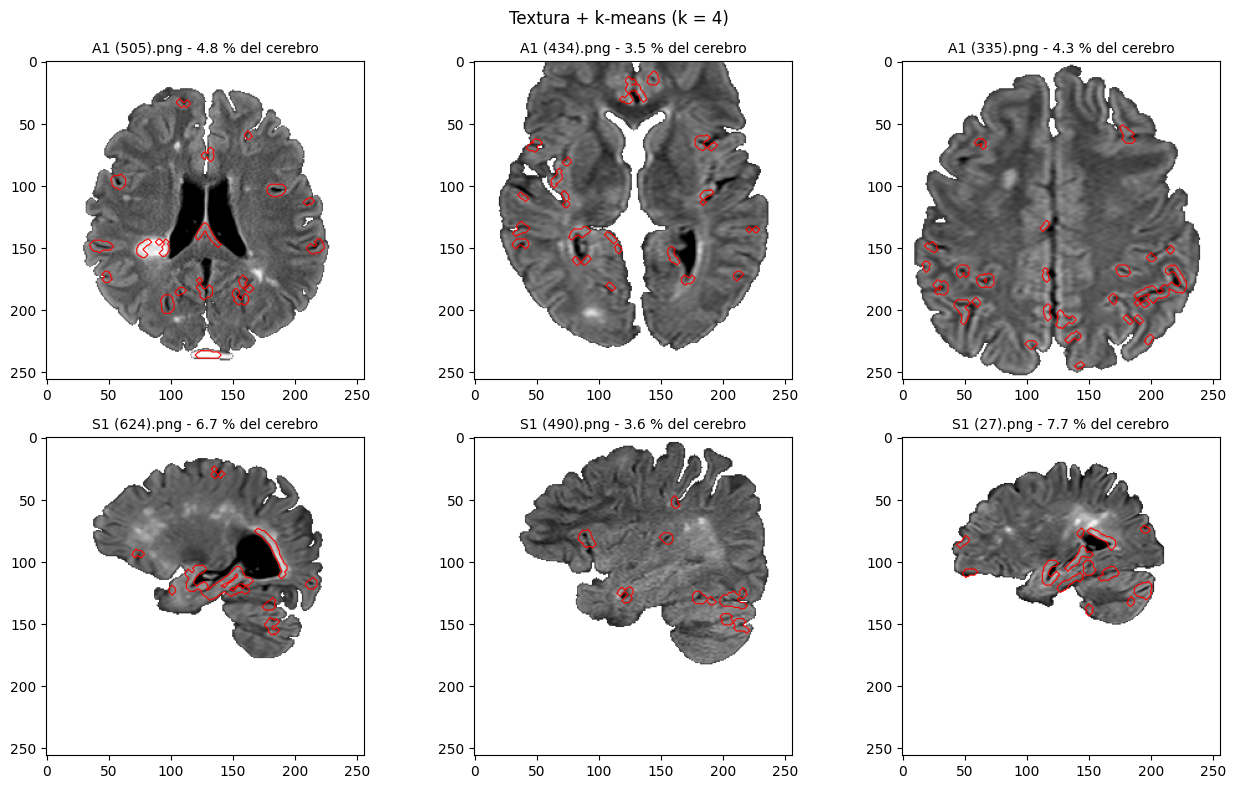

In [58]:
# Segmentación con K-means
assert PASO == 1, "Esta celda asume PASO = 1"
NOMBRES = ["Media local (z)", "Desv. estándar local", "Homogeneidad", "Cluster shade", "Entropía"]
K = 4
rad = VENT // 2

feats = {}   # nombre de imagen -> (features de los píxeles válidos, filas, columnas)
for nombre, (z, mask) in datos.items():
    mapas = mapas_textura(z, mask)
    pila = np.stack([mapas[n] for n in NOMBRES], axis=-1)
    valido = ~np.isnan(pila).any(axis=-1)
    ys, xs = np.nonzero(valido)
    feats[nombre] = (pila[valido], ys + rad, xs + rad)

X = np.vstack([f[0] for f in feats.values()]) # VerticalStack apila los mapas
med = np.median(X, axis=0)
iqr = np.percentile(X, 75, axis=0) - np.percentile(X, 25, axis=0) # Mediana e iqr de los mapas
escalar = lambda A: np.clip((A - med) / iqr, -5, 5)

km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(escalar(X))
etiquetas = km.labels_
lesion = int(np.argmax([X[etiquetas == k, 0].mean() for k in range(K)]))   # cluster con mayor media local

resumen = pd.DataFrame([X[etiquetas == k].mean(axis=0) for k in range(K)], columns=NOMBRES)
resumen.insert(0, "% de píxeles", [100 * np.mean(etiquetas == k) for k in range(K)])
resumen.index.name = "Cluster"
display(resumen.round(2))
print("Cluster elegido como lesión:", lesion)

def seg_kmeans(nombre, shape):
    F, ys, xs = feats[nombre]
    seg = np.zeros(shape, bool)
    seg[ys, xs] = km.predict(escalar(F)) == lesion
    seg = ndi.binary_opening(seg, structure=morphology.disk(APERTURA))   # misma limpieza que el método 2
    return morphology.remove_small_objects(seg, AREA_MIN)

fig, axs = plt.subplots(2, 3, figsize=(13, 8))
for ax, (nombre, (z, mask)) in zip(axs.ravel(), datos.items()):
    seg = seg_kmeans(nombre, z.shape)
    ax.imshow(np.where(mask, z, np.nan), cmap="gray", vmin=-3, vmax=5)
    if seg.any():
        ax.contour(seg.astype(float), levels=[0.5], colors="r", linewidths=0.8)
    ax.set_title(f"{nombre} - {100 * seg.sum() / mask.sum():.1f} % del cerebro", fontsize=10)
fig.suptitle(f"Textura + k-means (k = {K})")
plt.tight_layout()
plt.show()

,% de píxeles,Media local (z),Cluster shade
Cluster,,,
0,42.48,0.33,-1.38
1,7.35,-0.28,42.86
2,11.27,0.27,-23.79
3,38.90,-0.45,0.74


Cluster elegido como lesión: 0


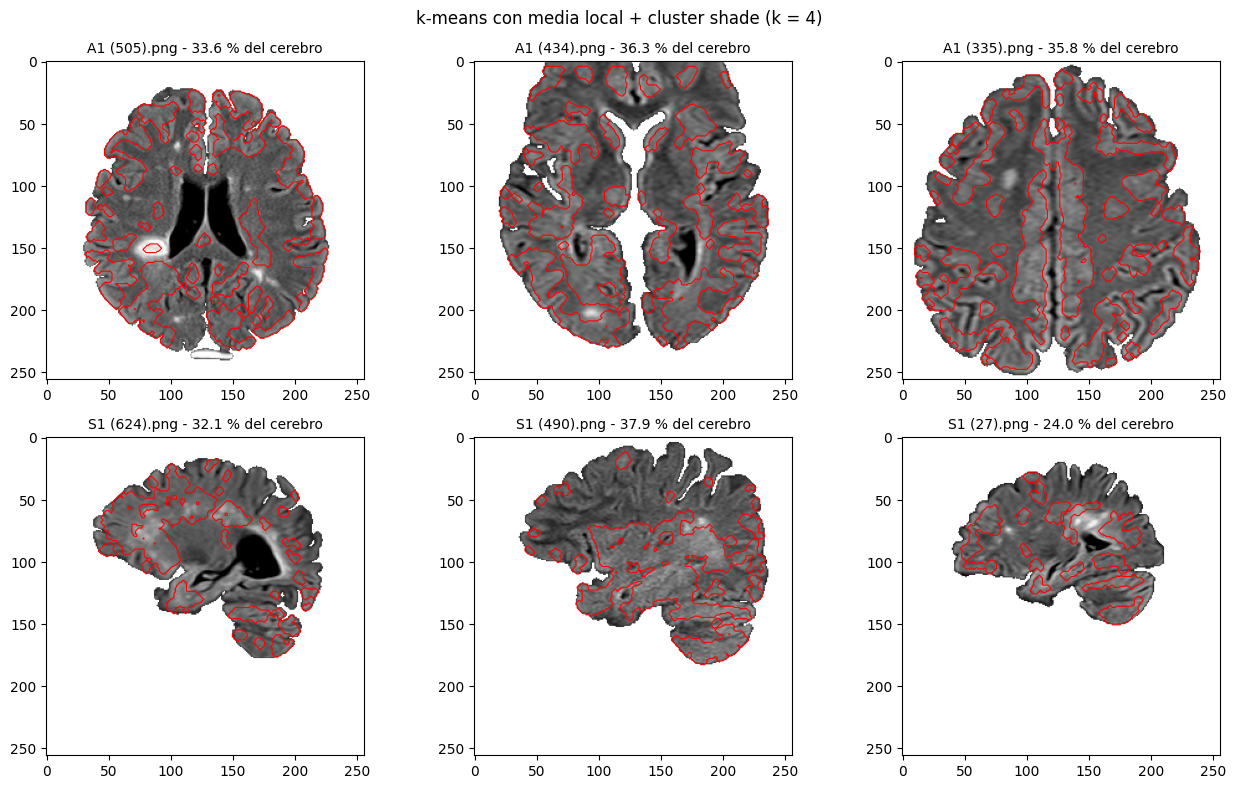

In [57]:
# Prueba 2: k-means solo con media local y cluster shade (reutiliza feats y X de la celda anterior)
COLS = [0, 3]                        # columnas de NOMBRES: 0 = media local, 3 = cluster shade
NOM2 = [NOMBRES[c] for c in COLS]
K2 = 4

X2 = X[:, COLS]
med2 = np.median(X2, axis=0)
iqr2 = np.percentile(X2, 75, axis=0) - np.percentile(X2, 25, axis=0)
escalar2 = lambda A: np.clip((A - med2) / iqr2, -5, 5)

km2 = KMeans(n_clusters=K2, n_init=10, random_state=0).fit(escalar2(X2))
etiq2 = km2.labels_
lesion2 = int(np.argmax([X2[etiq2 == k, 0].mean() for k in range(K2)]))   # cluster con mayor media local

resumen2 = pd.DataFrame([X2[etiq2 == k].mean(axis=0) for k in range(K2)], columns=NOM2)
resumen2.insert(0, "% de píxeles", [100 * np.mean(etiq2 == k) for k in range(K2)])
resumen2.index.name = "Cluster"
display(resumen2.round(2))
print("Cluster elegido como lesión:", lesion2)

def seg_kmeans2(nombre, shape):
    F, ys, xs = feats[nombre]
    seg = np.zeros(shape, bool)
    seg[ys, xs] = km2.predict(escalar2(F[:, COLS])) == lesion2
    seg = ndi.binary_opening(seg, structure=morphology.disk(APERTURA))   # misma limpieza que el método 2
    return morphology.remove_small_objects(seg, AREA_MIN)

fig, axs = plt.subplots(2, 3, figsize=(13, 8))
for ax, (nombre, (z, mask)) in zip(axs.ravel(), datos.items()):
    seg = seg_kmeans2(nombre, z.shape)
    ax.imshow(np.where(mask, z, np.nan), cmap="gray", vmin=-3, vmax=5)
    if seg.any():
        ax.contour(seg.astype(float), levels=[0.5], colors="r", linewidths=0.8)
    ax.set_title(f"{nombre} - {100 * seg.sum() / mask.sum():.1f} % del cerebro", fontsize=10)
fig.suptitle(f"k-means con media local + cluster shade (k = {K2})")
plt.tight_layout()
plt.show()

,% de píxeles,Media local (z),Desv. estándar local,Cluster shade
Cluster,,,,
0,74.84,-0.06,0.37,0.00
1,12.33,0.26,0.95,-23.43
2,3.65,-1.96,1.86,69.89
3,9.19,0.28,0.75,18.32


Cluster elegido como lesión: 3


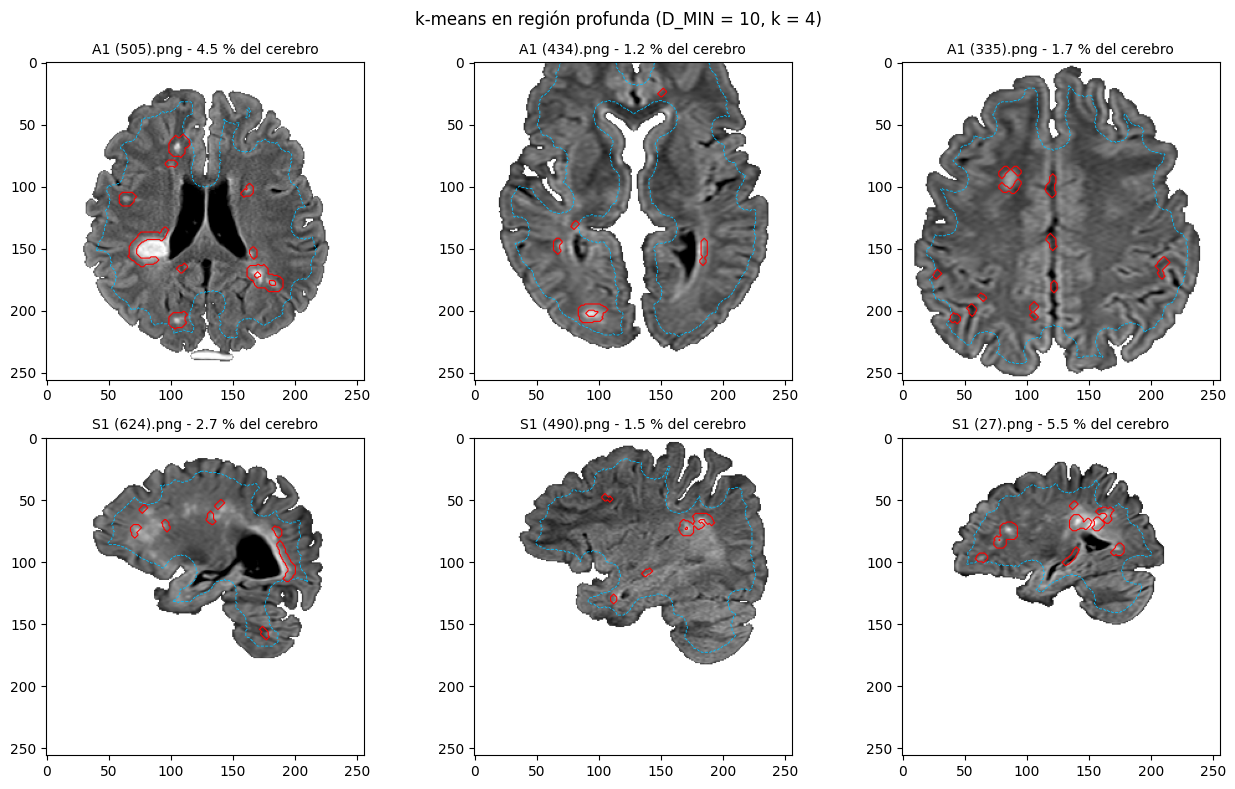

In [64]:
# Prueba 3: k-means solo en la región profunda (sin la cinta cortical), con media local + cluster shade
D_MIN = 10        # px: se descartan los píxeles a menos de D_MIN del borde del cerebro
K3 = 4
COLS = [0, 1, 3]     # media local y cluster shade

prof = {}         # nombre -> (features de los píxeles profundos, filas, columnas)
for nombre, (z, mask) in datos.items():
    F, ys, xs = feats[nombre]
    dist = ndi.distance_transform_edt(mask)
    ok = dist[ys, xs] > D_MIN
    prof[nombre] = (F[ok][:, COLS], ys[ok], xs[ok])

X3 = np.vstack([p[0] for p in prof.values()])
med3 = np.median(X3, axis=0)
iqr3 = np.percentile(X3, 75, axis=0) - np.percentile(X3, 25, axis=0)
escalar3 = lambda A: np.clip((A - med3) / iqr3, -5, 5)

km3 = KMeans(n_clusters=K3, n_init=10, random_state=0).fit(escalar3(X3))
etiq3 = km3.labels_
lesion3 = int(np.argmax([X3[etiq3 == k, 0].mean() for k in range(K3)]))   # cluster con mayor media local

resumen3 = pd.DataFrame([X3[etiq3 == k].mean(axis=0) for k in range(K3)], columns=[NOMBRES[c] for c in COLS])
resumen3.insert(0, "% de píxeles", [100 * np.mean(etiq3 == k) for k in range(K3)])
resumen3.index.name = "Cluster"
display(resumen3.round(2))
print("Cluster elegido como lesión:", lesion3)

def seg_kmeans3(nombre, shape):
    F, ys, xs = prof[nombre]
    seg = np.zeros(shape, bool)
    seg[ys, xs] = km3.predict(escalar3(F)) == lesion3
    seg = ndi.binary_opening(seg, structure=morphology.disk(APERTURA))
    return morphology.remove_small_objects(seg, AREA_MIN)

fig, axs = plt.subplots(2, 3, figsize=(13, 8))
for ax, (nombre, (z, mask)) in zip(axs.ravel(), datos.items()):
    seg = seg_kmeans3(nombre, z.shape)
    ax.imshow(np.where(mask, z, np.nan), cmap="gray", vmin=-3, vmax=5)
    ax.contour(ndi.distance_transform_edt(mask) > D_MIN, levels=[0.5], colors="deepskyblue", linewidths=0.6, linestyles="dashed")
    if seg.any():
        ax.contour(seg.astype(float), levels=[0.5], colors="r", linewidths=0.8)
    ax.set_title(f"{nombre} - {100 * seg.sum() / mask.sum():.1f} % del cerebro", fontsize=10)
fig.suptitle(f"k-means en región profunda (D_MIN = {D_MIN}, k = {K3})")
plt.tight_layout()
plt.show()

&ensp; Se calcularon mapas de textura sobre la imagen normalizada, con una ventana de 9 × 9 px, 32 niveles de gris y una GLCM promediada en los 4 ángulos (distancia 1): media local, desviación estándar local, energía, homogeneidad, contraste, cluster shade y entropía. La energía y el contraste se descartaron porque resaltaban el líquido ventricular y duplicaban a la desviación estándar, respectivamente. Los mapas seleccionados se escalaron de forma robusta (mediana e IQR) y se agruparon con k-means ajustado sobre los píxeles de las 6 imágenes; se eligió como "lesión" el cluster de mayor media local, con la misma limpieza (apertura y área mínima) que el método 2. Se probaron tres variantes:

| Variante | Atributos | Región | % del cerebro marcado |
|---|---|---|---|
| A | media, desv. estándar, homogeneidad, cluster shade, entropía (k = 4) | cerebro completo | 3,5 % – 7,7 % |
| B | media local y cluster shade (k = 4) | cerebro completo | 24 % – 38 % |
| C | media local y cluster shade (k = 3) | región profunda (sin los 10 px del borde) | 3,4 % – 6,2 % |

**Resultado.** Ninguna variante logró aislar las lesiones. A sobresegmentó con manchas dispersas por la corteza y los surcos. En B el cluster elegido fue la **corteza**, que en FLAIR es más brillante que la sustancia blanca y ocupa mucha más área que las lesiones. En C, al quitar la cinta cortical, los clusters resultantes se diferenciaban casi exclusivamente por el signo del cluster shade (centroides de −23 y +36 con medias locales de z entre −0,34 y 0,27), es decir, agrupaban los dos lados de un borde y no tejido lesionado.

**Interpretación.** Las lesiones representan menos del 3 % de los píxeles y k-means minimiza la varianza interna, por lo que reparte sus clusters entre las estructuras dominantes (líquido, sustancia blanca, corteza, bordes) y no dedica uno a un grupo pequeño y extremo. Además, los atributos de textura describen sobre todo estructura y no brillo, y dentro de una lesión la textura se parece a la de la sustancia blanca normal. Concluimos que, en esta implementación, la información de textura no agregó valor a la de intensidad, que fue el atributo más informativo, y que sin anotaciones no es posible entrenar un clasificador supervisado que lo aproveche.

## Conclusiones de la segmentación

Evaluados de forma cualitativa sobre 6 cortes de MS (3 axiales y 3 sagitales) y sin ground truth:

- **Region growing** es conservador: detecta las lesiones más evidentes pero no las tenues, y marca bordes de ventrículos y de la cisura interhemisférica.
- **Umbralización adaptativa** detecta además manchas tenues, porque compara cada píxel con su entorno, pero genera falsos positivos finos y alargados en los bordes. Una **apertura morfológica** los elimina casi por completo manteniendo las lesiones evidentes, y fue **el mejor método de los probados**.
- **Textura + k-means** sobresegmenta y no aísla lesiones.

&ensp; Se adopta la umbralización adaptativa con apertura (σ = 15 px, desplazamiento de 1 unidad de z, z mínimo 1, apertura de radio 2 px y área mínima de 50 px) como método de segmentación para la extracción de características.